# Predicting HDB Resale Flat Prices in Singapore

**Author:** Rio  |  **Theme:** Smart cities and urban analytics

**Question:** Can we predict the price of an HDB resale flat from its size, floor, remaining lease and location, and which of these matter most?

| Section | What happens | Rubric row |
|---|---|---|
| 0 | Dataset, problem, metrics, success criteria | Dataset & Problem Definition |
| 1–2 | Load the data, check quality, turn text into numbers | Preprocessing & Pipeline |
| 3 | Exploratory data analysis | EDA, PCA & Visualisation |
| 4–5 | Train/test split, then PCA *before* modelling | EDA, PCA & Visualisation |
| 6 | Preprocessing pipeline | Preprocessing & Pipeline |
| 7 | Baseline and three model types, with cross-validation | Model Training & Optimisation |
| 8 | AutoML with FLAML | Use of AutoML |
| 9–10 | Tuning with Optuna, final test | Model Training & Optimisation |
| 11 | Explainable AI with SHAP | XAI & Interpretation |
| 12–13 | Save the model, conclusions, reflection | Documentation / Presentation |

## 0. Dataset and problem

### 0.1 Dataset

| Item | Details |
|---|---|
| Name | Resale flat prices based on registration date from Jan-2017 onwards |
| Publisher | Housing & Development Board (HDB), via data.gov.sg |
| Link | https://data.gov.sg/datasets/d_8b84c4ee58e3cfc0ece0d773c8ca6abc/view |
| Licence | Singapore Open Data Licence v1.0 (free to use and share, with credit) |
| Rows used | 46,307 resale transactions, **January 2025 to October 2026** |
| Columns | 10 inputs + 1 target (`resale_price`) |
| Theme fit | Housing is a core smart-city question: where people live, what homes cost and how lease decay affects value |

We keep only 2025–2026 so the data is **recent** and the file stays small (about 4.5 MB). The full file goes back to 2017.

### 0.2 The problem

HDB flats are home to most Singaporeans. Buyers, sellers and planners all want to know: **what is a fair price for this flat?**

- **ML task:** regression (predicting a number).
- **Target:** `resale_price` in Singapore dollars.
- **Inputs:** town, flat type, floor range, floor area, flat model, lease start year, remaining lease and month of sale.
- **Why regression?** The answer is a price, not a category.

### 0.3 Metrics and why we chose them

| Metric | Plain meaning | Why we use it |
|---|---|---|
| **MAE** (main metric) | Average size of the error, in S$ | Easy to explain: "on average we are $X off" |
| **MAPE** | Average error as a % of the price | Fair across cheap and expensive flats: $30k off a $300k flat is worse than $30k off a $1M flat |
| **RMSE** | Like MAE, but big misses count more | Shows whether there are a few very large errors |
| **R²** | Share of price differences the model explains (1 = perfect) | Standard summary of fit |

### 0.4 Success criteria (set before modelling)

1. Beat the baseline (always predicting the average price) and a linear regression.
2. Test **R² ≥ 0.90**.
3. Test **MAPE ≤ 8%** (typical error under 8% of the price).
4. **No overfitting:** the test MAE should be within 10% of the cross-validation MAE.

We check these in Section 13.

## Setup

In [1]:
# Install the extra libraries if they are missing (needed on Colab)
!pip install -q flaml optuna shap lightgbm xgboost

In [2]:
# Import libraries
import os, re, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
from lightgbm import LGBMRegressor
from flaml import AutoML
import optuna, shap, joblib

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid")

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Settings
SEED = 42              # one seed for every random step, so results repeat
TEST_SIZE = 0.20       # 20% of sales kept back as the final test set
CV_FOLDS = 5           # 5-fold cross-validation on the training set
N_TRIALS = 20          # Optuna tuning trials
AUTOML_TRIALS = 50     # FLAML trials (a fixed number, so results repeat)
START_MONTH = "2025-01"

if os.environ.get("FAST_MODE") == "1":     # quick test run
    N_TRIALS, AUTOML_TRIALS = 4, 15

os.makedirs("../figures", exist_ok=True)
os.makedirs("../reports", exist_ok=True)
os.makedirs("../models", exist_ok=True)

def save(name):
    # save the current chart so it can be used in the slides
    plt.savefig(f"../figures/{name}.png", dpi=150, bbox_inches="tight")

## 1. Load the data

The notebook looks for `hdb_resale_2025_2026.csv` in the `data/` folder of the repo. **On Colab**, upload the file using the Files panel on the left (or the full file from data.gov.sg: the code keeps only sales from 2025 onwards either way).

In [4]:
# Find the data file (repo folder or Colab upload)
paths = ["../data/hdb_resale_2025_2026.csv", "data/hdb_resale_2025_2026.csv", "hdb_resale_2025_2026.csv",
         "ResaleflatpricesbasedonregistrationdatefromJan2017onwards.csv"]
path = next(p for p in paths if os.path.exists(p))
df = pd.read_csv(path)
df = df[df["month"] >= START_MONTH].reset_index(drop=True)   # keep 2025 onwards

print(f"Loaded {len(df):,} rows and {df.shape[1]} columns from {path}")
print("Months covered:", df["month"].min(), "to", df["month"].max())
df.head()

Loaded 46,307 rows and 11 columns from ../data/hdb_resale_2025_2026.csv
Months covered: 2025-01 to 2026-10


,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price
0,2025-05,ANG MO KIO,2 ROOM,406,ANG MO KIO AVE 10,04 TO 06,44.0,Improved,1979,53 years 01 month,340000.0
1,2025-08,ANG MO KIO,2 ROOM,406,ANG MO KIO AVE 10,07 TO 09,44.0,Improved,1979,52 years 10 months,353000.0
2,2025-01,ANG MO KIO,2 ROOM,314,ANG MO KIO AVE 3,10 TO 12,44.0,Improved,1978,52 years 02 months,318000.0
3,2025-03,ANG MO KIO,2 ROOM,314,ANG MO KIO AVE 3,10 TO 12,44.0,Improved,1978,51 years 11 months,338000.0
4,2025-03,ANG MO KIO,2 ROOM,323,ANG MO KIO AVE 3,07 TO 09,44.0,Improved,1977,51 years 04 months,300000.0


**What each column means**

| Column | Meaning |
|---|---|
| `month` | Month the resale was registered |
| `town` | HDB town (26 towns) |
| `flat_type` | 1 ROOM to 5 ROOM, EXECUTIVE, MULTI-GENERATION |
| `block`, `street_name` | Address |
| `storey_range` | Floor range, e.g. "07 TO 09" |
| `floor_area_sqm` | Floor area in square metres |
| `flat_model` | Design type, e.g. Model A, Improved, Premium Apartment, DBSS |
| `lease_commence_date` | Year the 99-year lease started |
| `remaining_lease` | Lease left at the time of sale, e.g. "61 years 04 months" |
| `resale_price` | **Target:** sale price in S$ |

## 2. Data-quality check

In [5]:
# Column types, blank values and duplicates
print(df.dtypes, "\n")
print("Blank values per column:\n", df.isna().sum(), "\n")
print("Duplicate rows:", df.duplicated().sum())

month                      str
town                       str
flat_type                  str
block                      str
street_name                str
storey_range               str
floor_area_sqm         float64
flat_model                 str
lease_commence_date      int64
remaining_lease            str
resale_price           float64
dtype: object 

Blank values per column:
 month                  0
town                   0
flat_type              0
block                  0
street_name            0
storey_range           0
floor_area_sqm         0
flat_model             0
lease_commence_date    0
remaining_lease        0
resale_price           0
dtype: int64 

Duplicate rows: 22


In [6]:
# Look at the categories, including rare ones
for col in ["flat_type", "flat_model"]:
    print(df[col].value_counts(), "\n")
print("Number of towns:", df["town"].nunique())
print("Storey ranges:", sorted(df["storey_range"].unique()))

flat_type
4 ROOM              20133
3 ROOM              10989
5 ROOM              10839
EXECUTIVE            2865
2 ROOM               1454
1 ROOM                 14
MULTI-GENERATION       13
Name: count, dtype: int64 

flat_model
Model A                   18472
Improved                  11103
New Generation             5123
Premium Apartment          4408
Simplified                 1709
Apartment                  1432
Maisonette                 1124
Standard                   1121
DBSS                        629
Model A2                    475
2-room                      355
Adjoined flat                75
Type S1                      72
Model A-Maisonette           70
3Gen                         38
Premium Apartment Loft       32
Type S2                      27
Terrace                      17
Multi Generation             13
Premium Maisonette            7
Improved-Maisonette           5
Name: count, dtype: int64 

Number of towns: 26
Storey ranges: ['01 TO 03', '04 TO 06', '07 TO 09

**What we found and what we decided**
- **No blank values** in any column, so nothing needs filling. The pipeline still includes a "fill blanks" step so it will not break on future data.
- **22 duplicate rows.** These are most likely two different flats in the same block, on the same floor range, sold in the same month for the same price (the data has no unit number). **Decision: keep them**; 22 rows out of 46,307 make no difference either way.
- **Rare categories:** only 14 "1 ROOM" and 13 "MULTI-GENERATION" sales, and several flat models with fewer than 50 sales (e.g. Terrace 17, Premium Maisonette 7). **Decision:** flat type becomes a number of rooms (Section 2.1), and rare flat models are grouped together in the pipeline (Section 6).
- **Text that hides numbers:** `storey_range` ("07 TO 09") and `remaining_lease` ("61 years 04 months") are text. **Decision:** convert them to numbers (Section 2.1).
- **Address columns** (`block`, `street_name`) have thousands of different values. **Decision:** leave them out; `town` already gives the location.

### 2.1 Turn text columns into numbers

Some useful information is stored as text, so we convert it. These steps only **reshape each row on its own** (no averages or counts are learned from the data), so it is safe to do them before the train/test split.

| New column | From | How |
|---|---|---|
| `storey_mid` | `storey_range` | middle floor: "07 TO 09" → 8 |
| `remaining_lease_years` | `remaining_lease` | "61 years 04 months" → 61.33 |
| `rooms` | `flat_type` | 1 ROOM → 1 … 5 ROOM → 5, EXECUTIVE → 6, MULTI-GENERATION → 7 |
| `flat_age` | sale year − `lease_commence_date` | age of the flat when sold |
| `months_since_start` | `month` | 0 for Jan 2025, 1 for Feb 2025, … (captures price trends) |
| `mature_estate` | `town` | 1 if the town is one of HDB's older "mature" estates, else 0 |

In [7]:
# HDB's mature estates (older towns, usually closer to the city)
MATURE = ["ANG MO KIO", "BEDOK", "BISHAN", "BUKIT MERAH", "BUKIT TIMAH", "CENTRAL AREA", "CLEMENTI",
          "GEYLANG", "KALLANG/WHAMPOA", "MARINE PARADE", "PASIR RIS", "QUEENSTOWN", "SERANGOON",
          "TAMPINES", "TOA PAYOH"]
ROOMS = {"1 ROOM": 1, "2 ROOM": 2, "3 ROOM": 3, "4 ROOM": 4, "5 ROOM": 5, "EXECUTIVE": 6, "MULTI-GENERATION": 7}

def lease_to_years(text):
    # "61 years 04 months" -> 61.33
    numbers = [int(n) for n in re.findall(r"\d+", text)]
    years = numbers[0]
    months = numbers[1] if len(numbers) > 1 else 0
    return years + months / 12

df["storey_mid"] = df["storey_range"].str[:2].astype(int) + 1
df["remaining_lease_years"] = df["remaining_lease"].apply(lease_to_years)
df["rooms"] = df["flat_type"].map(ROOMS)
df["sale_date"] = pd.to_datetime(df["month"])
df["flat_age"] = df["sale_date"].dt.year - df["lease_commence_date"]
df["months_since_start"] = (df["sale_date"].dt.year - 2025) * 12 + df["sale_date"].dt.month - 1
df["mature_estate"] = df["town"].isin(MATURE).astype(int)

df[["storey_range", "storey_mid", "remaining_lease", "remaining_lease_years", "flat_type", "rooms", "flat_age"]].head()

,storey_range,storey_mid,remaining_lease,remaining_lease_years,flat_type,rooms,flat_age
0,04 TO 06,5,53 years 01 month,53.083333,2 ROOM,2,46
1,07 TO 09,8,52 years 10 months,52.833333,2 ROOM,2,46
2,10 TO 12,11,52 years 02 months,52.166667,2 ROOM,2,47
3,10 TO 12,11,51 years 11 months,51.916667,2 ROOM,2,47
4,07 TO 09,8,51 years 04 months,51.333333,2 ROOM,2,48


## 3. Exploratory data analysis (EDA)

- **Univariate:** one variable at a time (3.1–3.3)
- **Bivariate:** each variable against the price (3.4–3.6)
- **Multivariate:** several variables together (3.7–3.8, and PCA in Section 5)

### 3.1 The target: resale price (univariate)

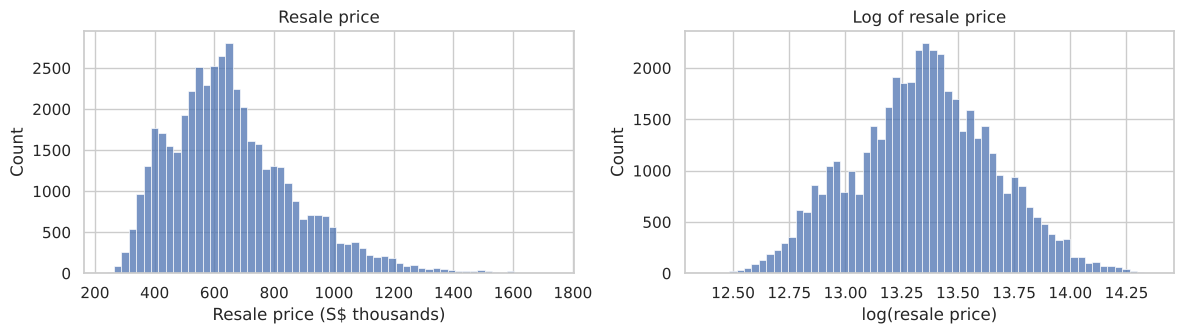

count      46307.0
mean      658644.0
std       210498.0
min       238888.0
25%       510000.0
50%       630000.0
75%       775000.0
max      1728000.0
Name: resale_price, dtype: float64
Skewness: price 0.92 | log price 0.03


In [8]:
# Distribution of the price, on a normal and a log scale
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
sns.histplot(df["resale_price"] / 1000, bins=60, ax=axes[0])
axes[0].set_xlabel("Resale price (S$ thousands)")
axes[0].set_title("Resale price")
sns.histplot(np.log(df["resale_price"]), bins=60, ax=axes[1])
axes[1].set_xlabel("log(resale price)")
axes[1].set_title("Log of resale price")
plt.tight_layout(); save("01_price_distribution"); plt.show()

print(df["resale_price"].describe().round(0))
print("Skewness: price", round(df["resale_price"].skew(), 2), "| log price", round(np.log(df["resale_price"]).skew(), 2))

**Insight:**
- The median flat sold for **S$630,000**; prices range from S$238,888 to S$1,728,000.
- Prices are **right-skewed** (skewness 0.92): most flats cost S$500k–775k, with a long tail of expensive flats. After taking the log, the shape is almost symmetric (skewness 0.03).
- **Decision:** the models will learn **log(price)**. This stops the few very expensive flats from dominating, and it means the models learn *percentage* effects, which suit prices better.

### 3.2 Summary statistics (univariate)

In [9]:
num_cols = ["resale_price", "floor_area_sqm", "storey_mid", "remaining_lease_years", "flat_age", "rooms"]
summary = df[num_cols].describe().T
summary["skew"] = df[num_cols].skew()
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
resale_price,46307.0,658643.69,210498.43,238888.00,510000.00,630000.0,775000.0,1728000.0,0.92
floor_area_sqm,46307.0,95.47,23.96,31.00,75.00,93.0,112.0,195.0,0.19
storey_mid,46307.0,8.94,6.05,2.00,5.00,8.0,11.0,50.0,1.57
remaining_lease_years,46307.0,72.17,15.35,39.08,58.92,71.5,88.5,96.0,-0.02
flat_age,46307.0,26.93,15.31,3.00,11.00,28.0,40.0,60.0,0.01
rooms,46307.0,4.06,0.92,1.00,3.00,4.0,5.0,7.0,0.12


**Insight:**
- **Floor area** runs from 31 to 195 sqm (median 93 sqm, a typical 4-room flat).
- **Floor:** the median sale is around the 8th floor, but a few blocks go up to the 50th, hence the right skew (1.57).
- **Remaining lease** runs from 39 to 96 years (median 71.5). Flats are 3 to 60 years old when sold.
- All values are realistic, so there are no impossible values to remove.

### 3.3 Outliers (univariate)

resale_price: 1,086 outliers (2.3%)
floor_area_sqm: 103 outliers (0.2%)

Most common flat types among high-price outliers:
 flat_type
5 ROOM       561
4 ROOM       323
EXECUTIVE    195
Name: count, dtype: int64

Most common towns among high-price outliers:
 town
TOA PAYOH       179
QUEENSTOWN      168
BUKIT MERAH     128
CENTRAL AREA     97
CLEMENTI         96
Name: count, dtype: int64


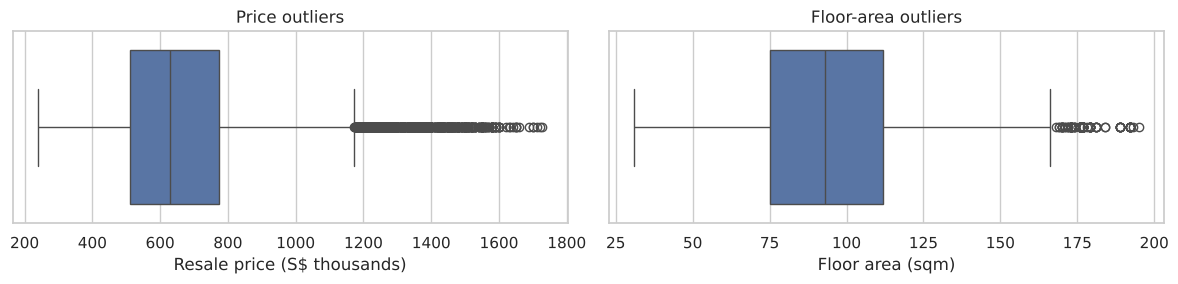

In [10]:
# Count outliers with the IQR rule: below Q1 - 1.5*IQR or above Q3 + 1.5*IQR
for col in ["resale_price", "floor_area_sqm"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers = df[(df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)]
    print(f"{col}: {len(outliers):,} outliers ({len(outliers) / len(df):.1%})")

big = df[df["resale_price"] > df["resale_price"].quantile(0.75) + 1.5 * (df["resale_price"].quantile(0.75) - df["resale_price"].quantile(0.25))]
print("\nMost common flat types among high-price outliers:\n", big["flat_type"].value_counts().head(3))
print("\nMost common towns among high-price outliers:\n", big["town"].value_counts().head(5))

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
sns.boxplot(x=df["resale_price"] / 1000, ax=axes[0]); axes[0].set_xlabel("Resale price (S$ thousands)")
sns.boxplot(x=df["floor_area_sqm"], ax=axes[1]); axes[1].set_xlabel("Floor area (sqm)")
axes[0].set_title("Price outliers"); axes[1].set_title("Floor-area outliers")
plt.tight_layout(); save("02_outliers"); plt.show()

**Insight and decision:**
- **1,086 price outliers (2.3%)**, all at the expensive end. They are mostly 5-room, 4-room and Executive flats in central towns (Toa Payoh, Queenstown, Bukit Merah, Central Area, Clementi). These are **real million-dollar HDB flats**, not data errors.
- **103 floor-area outliers (0.2%)** are large Executive and maisonette flats, also real.
- **Decision: keep all outliers.** Removing them would make the model unable to price exactly the flats people are most curious about. Their influence is reduced instead by modelling log(price), and tree models are not distorted by extreme values.

### 3.4 Price by flat type and town (bivariate)

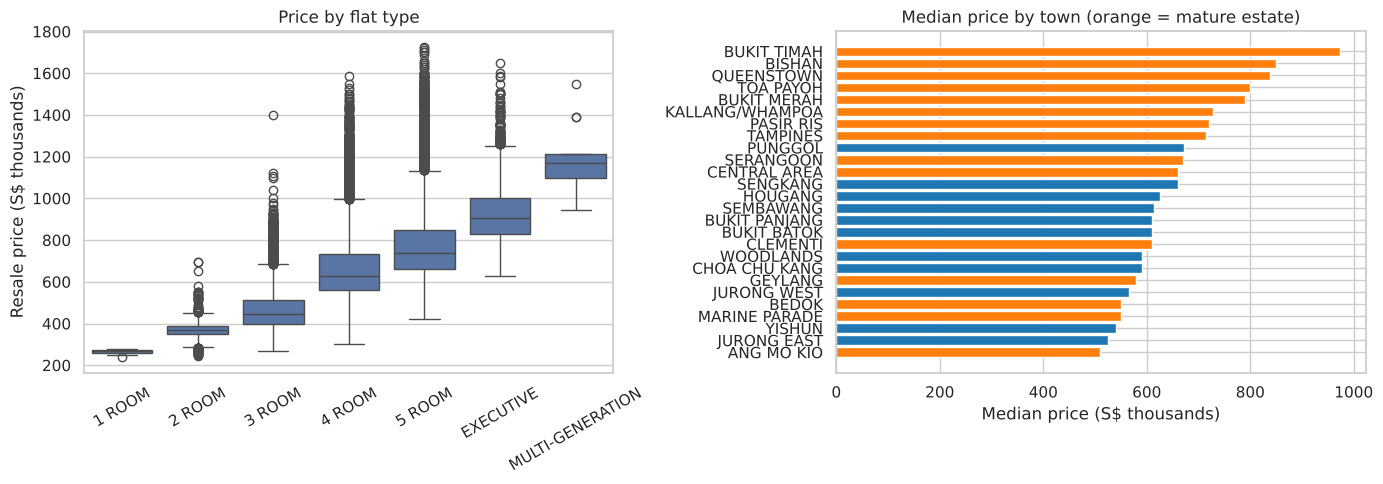

In [11]:
order = ["1 ROOM", "2 ROOM", "3 ROOM", "4 ROOM", "5 ROOM", "EXECUTIVE", "MULTI-GENERATION"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x="flat_type", y=df["resale_price"] / 1000, order=order, ax=axes[0])
axes[0].set_ylabel("Resale price (S$ thousands)"); axes[0].set_xlabel("")
axes[0].set_title("Price by flat type"); axes[0].tick_params(axis="x", rotation=30)

town_median = df.groupby("town")["resale_price"].median().sort_values() / 1000
colors = ["tab:orange" if t in MATURE else "tab:blue" for t in town_median.index]
axes[1].barh(town_median.index, town_median.values, color=colors)
axes[1].set_xlabel("Median price (S$ thousands)")
axes[1].set_title("Median price by town (orange = mature estate)")
plt.tight_layout(); save("03_price_by_type_and_town"); plt.show()

**Insight:**
- **Flat type is the biggest single driver:** the median price climbs from S$444k (3-room) to S$630k (4-room), S$740k (5-room) and S$908k (Executive).
- **Town matters too:** Bukit Timah (S$974k), Bishan (S$849k) and Queenstown (S$839k) have the highest medians; Ang Mo Kio (S$510k), Jurong East and Yishun the lowest.
- **Careful:** some mature estates, like Ang Mo Kio and Bedok, are near the *bottom*. That is because they have many older, smaller flats (51% of Ang Mo Kio sales are 3-room flats). A town's median mixes flat sizes and ages together, so we need a model that looks at all features **at the same time**.

### 3.5 Price against size, floor and lease (bivariate)

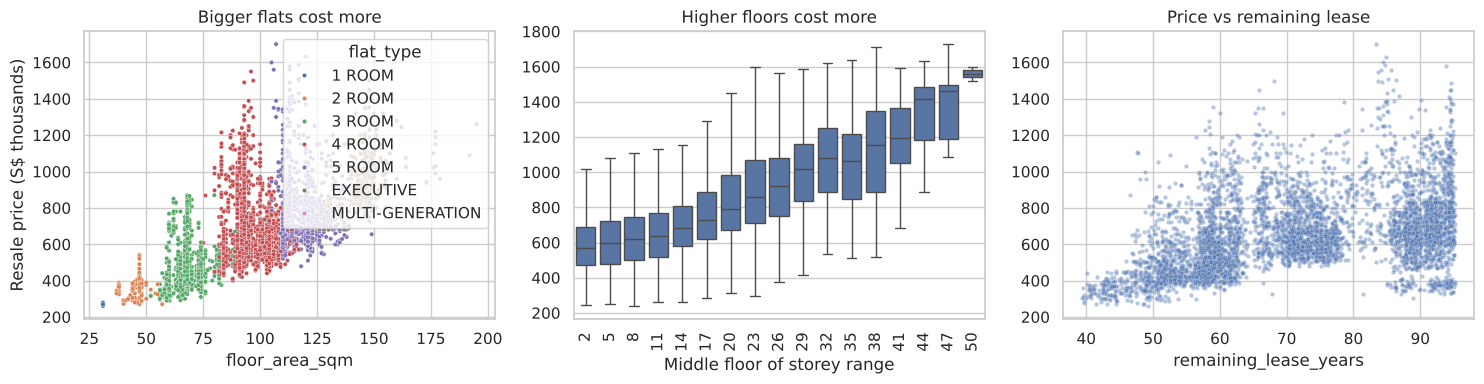

In [12]:
sample = df.sample(5000, random_state=SEED)      # a sample keeps the scatter plots readable
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.scatterplot(data=sample, x="floor_area_sqm", y=sample["resale_price"] / 1000, hue="flat_type",
                hue_order=order, s=10, ax=axes[0])
axes[0].set_ylabel("Resale price (S$ thousands)"); axes[0].set_title("Bigger flats cost more")
sns.boxplot(data=df, x="storey_mid", y=df["resale_price"] / 1000, ax=axes[1], showfliers=False)
axes[1].set_ylabel(""); axes[1].set_xlabel("Middle floor of storey range"); axes[1].set_title("Higher floors cost more")
axes[1].tick_params(axis="x", rotation=90)
sns.scatterplot(data=sample, x="remaining_lease_years", y=sample["resale_price"] / 1000, s=10, alpha=0.4, ax=axes[2])
axes[2].set_ylabel(""); axes[2].set_title("Price vs remaining lease")
plt.tight_layout(); save("04_price_vs_size_floor_lease"); plt.show()

**Insight:**
- **Size:** bigger flats cost more, and the colours show each flat type as its own band.
- **Floor:** the median price rises steadily with height, from about S$570k on the lowest floors to over S$1M above the 28th floor. Very high floors are rare and mostly in new central blocks.
- **Remaining lease:** the relationship is **not a straight line**. Flats with 85+ years left are expensive, but so are some older flats with 60–70 years left (in central towns). This kind of curve is hard for linear regression and easier for tree models.

### 3.6 Statistical tests (bivariate)

- **Numbers vs price:** Spearman correlation (works on ranks, so skew and outliers don't distort it).
- **Categories vs price:** one-way **ANOVA** on log price, with **eta squared (η²)** as the effect size: the share of price variation explained by the category (0 = none, 1 = all). We use log price because ANOVA works best when the groups are roughly normal.

With 46,000 rows almost every test is "significant", so we read the **effect sizes**.

In [13]:
# Spearman correlation of each number with price
for col in ["floor_area_sqm", "rooms", "storey_mid", "remaining_lease_years", "flat_age", "months_since_start"]:
    rho, p = stats.spearmanr(df[col], df["resale_price"])
    print(f"{col:24s} rho = {rho:+.2f}   p = {p:.1e}")

# One-way ANOVA of log price across categories, with eta squared
log_price = np.log(df["resale_price"])
print()
for col in ["flat_type", "town", "flat_model", "mature_estate"]:
    groups = [log_price[df[col] == g] for g in df[col].unique()]
    f, p = stats.f_oneway(*groups)
    ss_between = sum(len(g) * (g.mean() - log_price.mean()) ** 2 for g in groups)
    eta_sq = ss_between / ((log_price - log_price.mean()) ** 2).sum()
    print(f"{col:14s} F = {f:9.1f}   p = {p:.1e}   eta squared = {eta_sq:.2f}")

floor_area_sqm           rho = +0.69   p = 0.0e+00
rooms                    rho = +0.72   p = 0.0e+00
storey_mid               rho = +0.28   p = 0.0e+00
remaining_lease_years    rho = +0.44   p = 0.0e+00
flat_age                 rho = -0.45   p = 0.0e+00
months_since_start       rho = +0.03   p = 1.3e-13

flat_type      F =    8875.1   p = 0.0e+00   eta squared = 0.53
town           F =     209.2   p = 0.0e+00   eta squared = 0.10
flat_model     F =    1033.9   p = 0.0e+00   eta squared = 0.31
mature_estate  F =    1334.8   p = 4.0e-288   eta squared = 0.03


**Insight:**
- **Numbers:** rooms (ρ = 0.72) and floor area (0.69) are most strongly linked to price, then flat age (−0.45: older = cheaper), remaining lease (+0.44) and floor (+0.28). The month of sale barely matters (+0.03).
- **Categories:** flat type explains **53%** of the variation in log price (η² = 0.53), flat model 31%, town 10% and mature estate on its own only 3%.
- **Size comes first, then age and location.**

### 3.7 Price trend over time (multivariate: time × flat type)

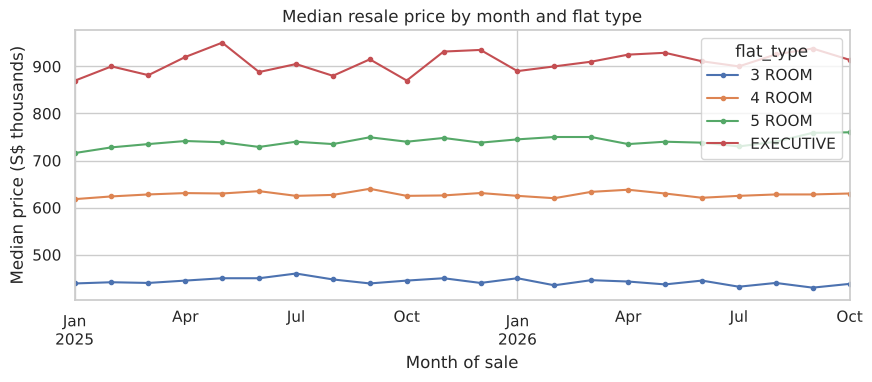

Change from the first 3 to the last 3 months:
 flat_type
3 ROOM       -0.9%
4 ROOM        0.9%
5 ROOM        3.7%
EXECUTIVE     4.8%
dtype: str


In [14]:
trend = df.groupby(["sale_date", "flat_type"])["resale_price"].median().unstack()[["3 ROOM", "4 ROOM", "5 ROOM", "EXECUTIVE"]]
(trend / 1000).plot(figsize=(10, 3.5), marker="o", markersize=3)
plt.ylabel("Median price (S$ thousands)"); plt.xlabel("Month of sale")
plt.title("Median resale price by month and flat type")
save("05_price_trend"); plt.show()

first, last = trend.iloc[:3].mean(), trend.iloc[-3:].mean()
print("Change from the first 3 to the last 3 months:\n", ((last / first - 1) * 100).round(1).astype(str) + "%")

**Insight:** prices were **stable** over these 22 months: median prices changed by only −0.9% (3-room) to +4.8% (Executive) between the first and last three months. So `months_since_start` should matter little, which matches its tiny correlation with price (+0.03). (A longer period, such as 2020–2024, would show a much stronger trend.)

### 3.8 Correlation between the numeric columns (multivariate)

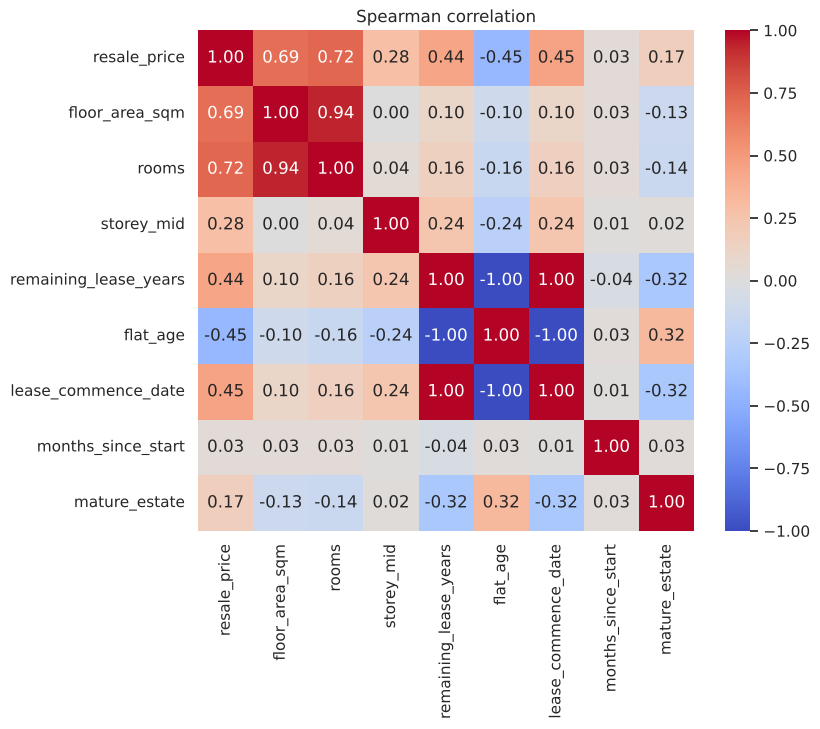

In [15]:
corr_cols = ["resale_price", "floor_area_sqm", "rooms", "storey_mid", "remaining_lease_years",
             "flat_age", "lease_commence_date", "months_since_start", "mature_estate"]
corr = df[corr_cols].corr(method="spearman")
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Spearman correlation")
save("06_correlation_heatmap"); plt.show()

**Insight:**
- **Floor area and rooms** are very strongly linked (0.94): both measure size.
- **Remaining lease, flat age and lease start year** are perfectly linked (±1.00): they are the **same information** written three ways (a 99-year lease minus the flat's age).
- Mature estates have older flats (−0.32 with remaining lease), and newer blocks tend to be taller (+0.24).

This redundancy is exactly what PCA (Section 5) will measure. It also tells us to keep **only one** of the three lease columns in the model.

## 4. Train/test split, before anything is fitted

We keep **20% of sales as the test set** and use it only once, in Section 10. Everything that learns from the data (scaling, PCA, AutoML, tuning) uses only the **training set**, with 5-fold cross-validation. This prevents **data leakage**.

In [16]:
FEATURES = ["town", "flat_model", "floor_area_sqm", "rooms", "storey_mid",
            "remaining_lease_years", "months_since_start", "mature_estate"]
TARGET = "resale_price"

X = df[FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=SEED)
cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)

print(f"Training set: {len(X_train):,} sales | Test set: {len(X_test):,} sales")
print(f"Median price - train: S${y_train.median():,.0f} | test: S${y_test.median():,.0f}")

Training set: 37,045 sales | Test set: 9,262 sales
Median price - train: S$630,000 | test: S$632,000


**Why these 8 features?** `lease_commence_date` and `flat_age` are left out because they carry the same information as `remaining_lease_years` (correlation about −1.00 / +1.00 in Section 3.8). `flat_type` is replaced by the number `rooms`. `block` and `street_name` are left out: they have thousands of values, and `town` already gives the location.

## 5. Principal Component Analysis (PCA), before modelling

**Why PCA?** Section 3.8 showed that some numeric columns move together (size and rooms; lease, age and start year). PCA combines correlated columns into new "components" and shows how much **independent** information the numbers really contain.

**How:** use the 7 numeric columns, **standardise** them (mean 0, standard deviation 1, so floor area in sqm doesn't dominate just because its numbers are bigger), and fit PCA on the **training set only**.

In [17]:
pca_cols = ["floor_area_sqm", "rooms", "storey_mid", "remaining_lease_years",
            "flat_age", "lease_commence_date", "months_since_start"]
train_rows = X_train.index

scaler = StandardScaler().fit(df.loc[train_rows, pca_cols])      # fit on training data only
Z = scaler.transform(df.loc[train_rows, pca_cols])
pca = PCA().fit(Z)

explained = pca.explained_variance_ratio_
print("Variance explained by each component:", explained.round(3))
print("Cumulative:", explained.cumsum().round(3))

Variance explained by each component: [0.447 0.277 0.143 0.127 0.006 0.    0.   ]
Cumulative: [0.447 0.724 0.867 0.994 1.    1.    1.   ]


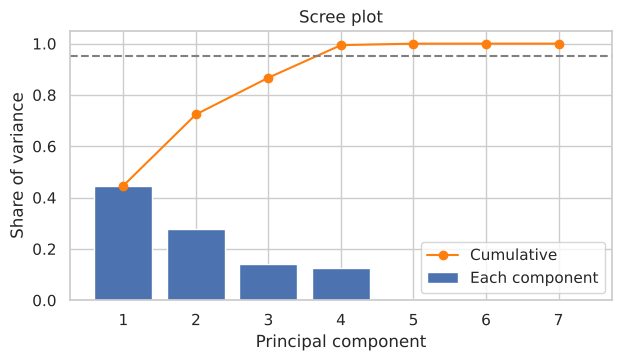

In [18]:
# Scree plot
plt.figure(figsize=(7, 3.5))
plt.bar(range(1, 8), explained, label="Each component")
plt.plot(range(1, 8), explained.cumsum(), marker="o", color="tab:orange", label="Cumulative")
plt.axhline(0.95, linestyle="--", color="grey")
plt.xlabel("Principal component"); plt.ylabel("Share of variance"); plt.legend()
plt.title("Scree plot")
save("07_pca_scree"); plt.show()

**Insight:** 7 columns, but **4 components keep 99.4% of the information** (the first 3 keep 86.7%). Components 5–7 carry almost nothing, which confirms that 3 of the 7 columns are copies of others.

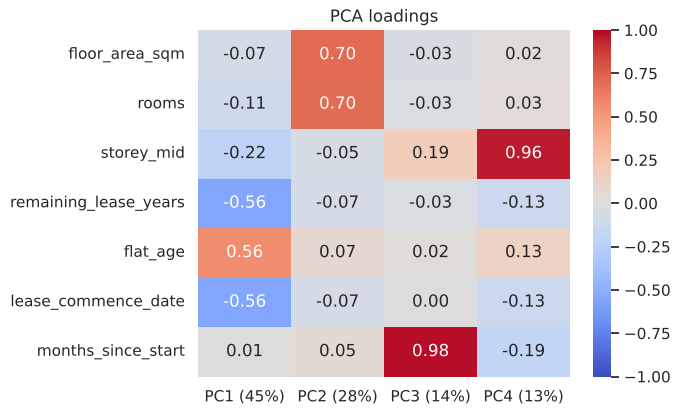

In [19]:
# Loadings: how much each original column contributes to each component
loadings = pd.DataFrame(pca.components_[:4].T, index=pca_cols,
                        columns=[f"PC{i+1} ({explained[i]:.0%})" for i in range(4)])
plt.figure(figsize=(6, 4.5))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("PCA loadings")
save("08_pca_loadings"); plt.show()

**Insight (what each component means):**
- **PC1 (45%) = flat age:** flat age (+0.56), remaining lease (−0.56) and lease start year (−0.56).
- **PC2 (28%) = size:** floor area (+0.70) and rooms (+0.70).
- **PC3 (14%) = time of sale** (0.98).
- **PC4 (13%) = floor height** (0.96).

So the numeric data really contains **four ideas**: age, size, when it was sold and how high it is.

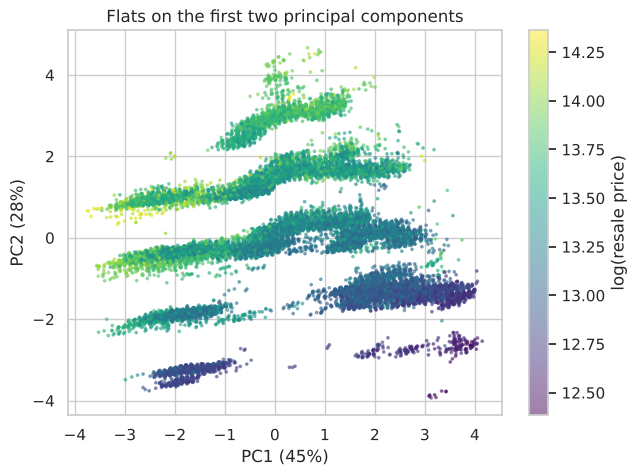

PC1: correlation with price = -0.54
PC2: correlation with price = +0.59
PC3: correlation with price = +0.03
PC4: correlation with price = +0.12


In [20]:
# Plot training flats on the first two components, coloured by price
P = pca.transform(Z)
plt.figure(figsize=(7, 5))
points = plt.scatter(P[:, 0], P[:, 1], c=np.log(y_train), s=3, cmap="viridis", alpha=0.5)
plt.colorbar(points, label="log(resale price)")
plt.xlabel(f"PC1 ({explained[0]:.0%})"); plt.ylabel(f"PC2 ({explained[1]:.0%})")
plt.title("Flats on the first two principal components")
save("09_pca_projection"); plt.show()

# How strongly is each component linked to price?
for i in range(4):
    rho, _ = stats.spearmanr(P[:, i], y_train)
    print(f"PC{i+1}: correlation with price = {rho:+.2f}")

**Insight:**
- The flats form **bands**, one for each flat type (size, PC2). Within each band, flats on the left (newer, PC1 low) are more expensive (yellow) than flats on the right (older).
- PC2 (size) is most linked to price (+0.59), then PC1 (age, −0.54). Time (PC3, +0.03) and floor (PC4, +0.12) matter much less.

### How PCA shapes the modelling (our decisions)
1. **Remove copies:** keep `remaining_lease_years` and drop `flat_age` and `lease_commence_date`, which PCA showed add nothing new.
2. **Test PCA as a model step:** in Section 7 we compare **PCA (95% variance) + linear regression** with plain linear regression.
3. **Keep original columns for the tree models,** so SHAP (Section 11) can explain prices in real terms ("+10 sqm adds about X%"), not "PC2 went up".

## 6. Preprocessing pipeline

All learned preprocessing goes inside a scikit-learn **Pipeline**, so in cross-validation it is re-fitted on each training fold (no leakage), and new flats get exactly the same treatment.

| Column type | Columns | Steps |
|---|---|---|
| Numbers | floor area, rooms, storey, remaining lease, months since start, mature estate | fill any blanks with the median → scale (linear model only) |
| Categories | town, flat model | fill blanks with the most common value → **one-hot encode**; categories with fewer than 50 training sales are grouped as "infrequent" |

- **Why fill blanks if there are none?** Future data might have some; the pipeline should not break.
- **Why group rare categories?** Flat models like "Terrace" (17 sales) are too rare to learn from reliably. All 26 towns have more than 50 sales, so only rare flat models are grouped.
- **Why scale only for the linear model?** Linear regression compares coefficients across columns, so scale matters. Tree models split on thresholds, so scale makes no difference, and unscaled values keep the SHAP plots in real units (sqm, years).

**Log target:** prices are right-skewed (Section 3.1), so every model learns **log(price)** and its predictions are turned back into dollars. This also means the models learn *percentage* effects, which suit prices better (an extra floor adds more dollars to an expensive flat).

In [21]:
NUM = ["floor_area_sqm", "rooms", "storey_mid", "remaining_lease_years", "months_since_start", "mature_estate"]
CAT = ["town", "flat_model"]

def make_preprocessor(scale):
    num_steps = [("fill", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    cat_steps = [("fill", SimpleImputer(strategy="most_frequent")),
                 ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50, sparse_output=False))]
    return ColumnTransformer([("num", Pipeline(num_steps), NUM), ("cat", Pipeline(cat_steps), CAT)],
                             verbose_feature_names_out=False)

def make_model(regressor, scale=False, extra_step=None):
    # preprocessing -> (optional PCA) -> model, which learns log(price)
    steps = [("prep", make_preprocessor(scale))]
    if extra_step is not None:
        steps.append(extra_step)
    steps.append(("model", regressor))
    return TransformedTargetRegressor(regressor=Pipeline(steps), func=np.log, inverse_func=np.exp)

# Check what the preprocessing produces (fitted on the training data only)
prep = make_preprocessor(scale=True).fit(X_train)
print("Features after preprocessing:", len(prep.get_feature_names_out()))
print(list(prep.get_feature_names_out()))

Features after preprocessing: 47
['floor_area_sqm', 'rooms', 'storey_mid', 'remaining_lease_years', 'months_since_start', 'mature_estate', 'town_ANG MO KIO', 'town_BEDOK', 'town_BISHAN', 'town_BUKIT BATOK', 'town_BUKIT MERAH', 'town_BUKIT PANJANG', 'town_BUKIT TIMAH', 'town_CENTRAL AREA', 'town_CHOA CHU KANG', 'town_CLEMENTI', 'town_GEYLANG', 'town_HOUGANG', 'town_JURONG EAST', 'town_JURONG WEST', 'town_KALLANG/WHAMPOA', 'town_MARINE PARADE', 'town_PASIR RIS', 'town_PUNGGOL', 'town_QUEENSTOWN', 'town_SEMBAWANG', 'town_SENGKANG', 'town_SERANGOON', 'town_TAMPINES', 'town_TOA PAYOH', 'town_WOODLANDS', 'town_YISHUN', 'flat_model_2-room', 'flat_model_Adjoined flat', 'flat_model_Apartment', 'flat_model_DBSS', 'flat_model_Improved', 'flat_model_Maisonette', 'flat_model_Model A', 'flat_model_Model A-Maisonette', 'flat_model_Model A2', 'flat_model_New Generation', 'flat_model_Premium Apartment', 'flat_model_Simplified', 'flat_model_Standard', 'flat_model_Type S1', 'flat_model_infrequent_sklearn

**Check:** the 8 inputs become **47 model features**: 6 numbers, 26 town columns and 15 flat-model columns. The 7 rarest flat models (fewer than 50 training sales each, such as Terrace and 3Gen) are grouped into one `flat_model_infrequent_sklearn` column.

## 7. Baseline and candidate models

Every model is scored the **same way**: 5-fold cross-validation on the training set. We also record the score on the **training folds**, to check for **overfitting** (a model that memorises the training data scores much better there than on new data).

| Model | Type | Why |
|---|---|---|
| **Baseline** | Always predicts the average price | The minimum any real model must beat |
| **Linear regression** | Linear | Simple and explainable; each feature has one effect |
| **PCA → linear regression** | Linear on components | Tests the PCA finding: does compressing the numbers help or hurt? |
| **Random Forest** | Many trees, averaged | Captures curves and interactions (e.g. size matters more in some towns) |
| **LightGBM** | Boosted trees | Usually the strongest on tables of data; fast |

In [22]:
SCORES = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error",
          "MAPE": "neg_mean_absolute_percentage_error", "R2": "r2"}
results = {}

def evaluate(name, model):
    # 5-fold cross-validation on the training set; also keep the training MAE to check overfitting
    s = cross_validate(model, X_train, y_train, cv=cv, scoring=SCORES, return_train_score=True)
    results[name] = {
        "CV MAE": -s["test_MAE"].mean(), "MAE sd": s["test_MAE"].std(),
        "CV RMSE": -s["test_RMSE"].mean(), "CV MAPE %": -s["test_MAPE"].mean() * 100,
        "CV R2": s["test_R2"].mean(), "Train MAE": -s["train_MAE"].mean(), "Fit time (s)": s["fit_time"].mean()}
    return results[name]

def show(names=None):
    table = pd.DataFrame(results).T
    table["Train/CV MAE"] = table["Train MAE"] / table["CV MAE"]     # well below 1 = memorising
    return table.loc[names or table.index].round({"CV MAE": 0, "MAE sd": 0, "CV RMSE": 0, "CV MAPE %": 2,
                                                  "CV R2": 3, "Train MAE": 0, "Fit time (s)": 1, "Train/CV MAE": 2})

In [23]:
evaluate("Baseline (average price)", DummyRegressor(strategy="mean"))
evaluate("Linear regression", make_model(LinearRegression(), scale=True))
evaluate("PCA (95%) → Linear regression", make_model(LinearRegression(), scale=True, extra_step=("pca", PCA(n_components=0.95))))
evaluate("Random Forest", make_model(RandomForestRegressor(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=SEED)))
evaluate("LightGBM (default)", make_model(LGBMRegressor(random_state=SEED, verbose=-1)))
show()

,CV MAE,MAE sd,CV RMSE,CV MAPE %,CV R2,Train MAE,Fit time (s),Train/CV MAE
Baseline (average price),162853.0,578.0,210789.0,27.20,-0.000,162850.0,0.0,1.00
Linear regression,48207.0,310.0,67438.0,7.23,0.898,48101.0,0.1,1.00
PCA (95%) → Linear regression,58300.0,699.0,83326.0,8.57,0.844,58240.0,0.2,1.00
Random Forest,29983.0,338.0,44007.0,4.47,0.956,16199.0,8.8,0.54
LightGBM (default),33684.0,340.0,48568.0,4.99,0.947,32209.0,0.3,0.96


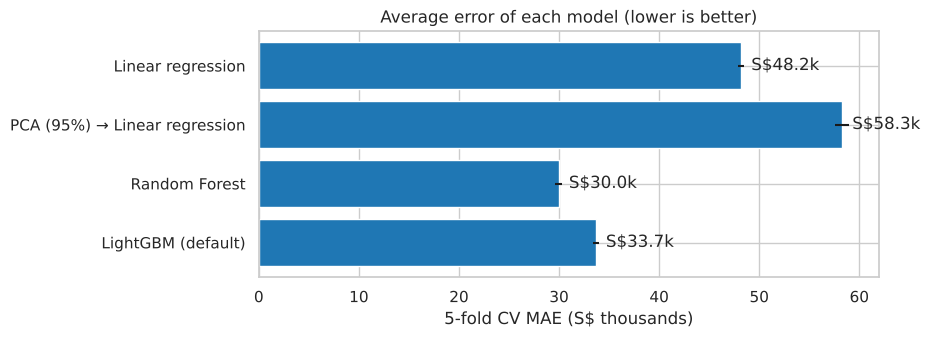

In [24]:
# Compare cross-validated MAE (lower is better); the error bars show the spread across the 5 folds
table = show().drop("Baseline (average price)")
plt.figure(figsize=(8, 3.2))
plt.barh(table.index, table["CV MAE"] / 1000, xerr=table["MAE sd"] / 1000, color="tab:blue")
for i, v in enumerate(table["CV MAE"] / 1000):
    plt.text(v + 1, i, f"S${v:.1f}k", va="center")
plt.xlabel("5-fold CV MAE (S$ thousands)"); plt.gca().invert_yaxis()
plt.title("Average error of each model (lower is better)")
save("10_model_comparison"); plt.show()

**Insight:**
- **Every model beats the baseline by far.** Always guessing the average price is S$162,853 off on average (27% error).
- **Linear regression** gets to S$48,207 (7.2% error, R² 0.898). That is good, but it treats every effect as a straight line.
- **PCA + linear regression is worse** (S$58,300). Keeping 95% of the variance throws away information that matters for price (for example the storey component), so **PCA helps us understand the data but does not help this model**.
- **Tree models are clearly best:** Random Forest S$29,983 (4.5% error) and LightGBM S$33,684. They capture curves and combinations, such as size mattering differently in different towns.

**Overfitting check (Train/CV MAE column):**
- Linear models score the same on training and validation data (ratio 1.00): no memorising, but too simple.
- **Random Forest** is almost twice as accurate on its training data (ratio 0.54): it **memorises** part of the training set. It still scores well on unseen folds, but this is a warning sign.
- **LightGBM (default)** has a ratio of 0.96: very little memorising, but it is underfitting a little, which makes it a good candidate for **tuning** (Section 9).

## 8. AutoML with FLAML

**Tool:** Microsoft **FLAML**. It automatically tries several model families and their settings, and keeps the best. We chose it because it is fast, supports cross-validation and runs on current Colab (PyCaret, another popular tool, does not support the current Colab Python version).

**Set-up for this problem:**
- **Data:** the same preprocessed training features (tree version), from the **training set only**.
- **Target:** log(price), the same as our own models.
- **Metric:** MAE on log price, which is close to the average % error.
- **Validation:** 5-fold cross-validation, the same as our models.
- **Model families:** LightGBM, XGBoost, Random Forest, Extra Trees.
- **Repeatable:** a fixed number of trials and a fixed seed.

**How we use it:** as a **scout**. Its leaderboard tells us which model family to tune in Section 9, and its best model is re-checked on the test set in Section 10.

In [25]:
# Prepare the training features once, then let FLAML search
tree_prep = make_preprocessor(scale=False).fit(X_train)
X_train_tree = pd.DataFrame(tree_prep.transform(X_train), columns=tree_prep.get_feature_names_out())

automl = AutoML()
start = time.time()
automl.fit(X_train_tree, np.log(y_train), task="regression", metric="mae",
           max_iter=AUTOML_TRIALS, time_budget=-1, eval_method="cv", n_splits=CV_FOLDS,
           estimator_list=["lgbm", "xgboost", "rf", "extra_tree"], seed=SEED,
           log_file_name="../reports/flaml_log.txt", verbose=0)
print(f"FLAML ran {AUTOML_TRIALS} trials in {time.time() - start:.0f} s")
print("Best model family:", automl.best_estimator)
print("Best settings:", automl.best_config)

FLAML ran 50 trials in 69 s
Best model family: lgbm
Best settings: {'n_estimators': 557, 'num_leaves': 35, 'min_child_samples': 25, 'learning_rate': np.float64(0.3426059704004836), 'log_max_bin': 6, 'colsample_bytree': np.float64(0.8801612007790223), 'reg_alpha': np.float64(0.019414794545861702), 'reg_lambda': np.float64(1.3165525472670216)}


In [26]:
# Score FLAML's best model with the same 5-fold CV as our own models (MAE in S$)
flaml_model = make_model(automl.model.estimator)
evaluate(f"FLAML best ({automl.best_estimator})", flaml_model)
show()

,CV MAE,MAE sd,CV RMSE,CV MAPE %,CV R2,Train MAE,Fit time (s),Train/CV MAE
Baseline (average price),162853.0,578.0,210789.0,27.20,-0.000,162850.0,0.0,1.00
Linear regression,48207.0,310.0,67438.0,7.23,0.898,48101.0,0.1,1.00
PCA (95%) → Linear regression,58300.0,699.0,83326.0,8.57,0.844,58240.0,0.2,1.00
Random Forest,29983.0,338.0,44007.0,4.47,0.956,16199.0,8.8,0.54
LightGBM (default),33684.0,340.0,48568.0,4.99,0.947,32209.0,0.3,0.96
FLAML best (lgbm),30138.0,462.0,43648.0,4.52,0.957,20966.0,0.7,0.70


lgbm           4.52
xgboost        5.31
extra_tree     6.92
rf            10.26
Name: CV error on log price (≈ % error), dtype: float64


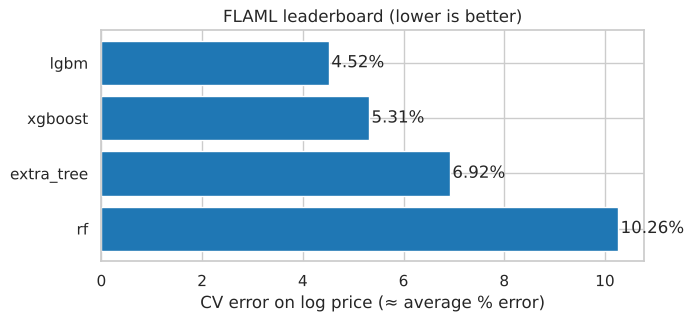

In [27]:
# Leaderboard: best CV error reached by each model family (error on log price ≈ average % error)
leaderboard = pd.Series({name: loss for name, loss in automl.best_loss_per_estimator.items() if loss is not None})
leaderboard = (leaderboard * 100).sort_values().rename("CV error on log price (≈ % error)")
print(leaderboard.round(2))

plt.figure(figsize=(7, 3))
plt.barh(leaderboard.index, leaderboard.values, color="tab:blue")
for i, v in enumerate(leaderboard.values):
    plt.text(v + 0.05, i, f"{v:.2f}%", va="center")
plt.gca().invert_yaxis(); plt.xlabel("CV error on log price (≈ average % error)")
plt.title("FLAML leaderboard (lower is better)")
save("11_automl_leaderboard"); plt.show()

**Interpreting the leaderboard:**
- **LightGBM wins clearly** (about 4.5% error), then XGBoost (5.3%), Extra Trees (6.9%) and Random Forest (10.3%).
- In our own S$ terms, FLAML's best LightGBM scores **S$30,138** CV MAE: better than default LightGBM (S$33,684), about the same as our Random Forest (S$29,983).
- **It confirms our plan:** boosted trees are the right family, so we tune **LightGBM** next. It is also fast and works directly with SHAP.
- **But read it critically:** FLAML ranks Random Forest *last* (10.3%), yet our own Random Forest reached 4.5%. With only 50 trials, FLAML spends most of its time on the most promising family and tries only small Random Forests. **The leaderboard reflects the search budget, not just the model families.**

**Limitations of AutoML:**
- It optimises **one number** and ignores explainability, speed and fairness.
- Results depend on the **budget and model list**: as above, a model family can look weak just because it got few trials.
- It reuses the **same folds many times**, so its best score is a little optimistic. That is why its model is re-tested on the untouched test set in Section 10.
- It **cannot prepare the data**: turning "07 TO 09" into a number, removing duplicate lease columns and choosing a log target were all manual steps.

## 9. Hyperparameter tuning: LightGBM with Optuna

**Method:** Bayesian optimisation with Optuna's **TPE sampler**, 20 trials. Each trial is scored by 5-fold CV MAE on the training set only.

**Why not grid search?** With 7 settings, even 3 values each means 3⁷ = 2,187 combinations. TPE learns from earlier trials and focuses on promising areas.

| Setting | Range | Why |
|---|---|---|
| `n_estimators` (number of trees) | 200–1000 | More, smaller steps usually generalise better |
| `learning_rate` | 0.01–0.2 (log scale) | From careful to fast learning |
| `num_leaves` | 15–127 (log scale) | Tree size: bigger trees capture more detail but can overfit |
| `min_child_samples` | 5–100 | Minimum flats per leaf; larger = less fitting to noise |
| `subsample`, `colsample_bytree` | 0.6–1.0 | Use random subsets of rows and columns to reduce overfitting |
| `reg_lambda` | 0.001–10 (log scale) | L2 penalty that keeps the model simple |

In [28]:
def objective(trial):
    # One trial: choose settings, then score them with 5-fold CV on the training set
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 200, 1000, step=100),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 127, log=True),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 100),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
    }
    model = make_model(LGBMRegressor(subsample_freq=1, random_state=SEED, verbose=-1, **params))
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error")
    return -scores["test_score"].mean()

study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
start = time.time()
study.optimize(objective, n_trials=N_TRIALS)
print(f"Tuning took {time.time() - start:.0f} s")
print(f"Best CV MAE: S${study.best_value:,.0f}")
best_params = study.best_params
best_params

Tuning took 188 s
Best CV MAE: S$28,352


{'n_estimators': 900,
 'learning_rate': 0.06054365855469246,
 'num_leaves': 68,
 'min_child_samples': 6,
 'subsample': 0.9879639408647978,
 'colsample_bytree': 0.9329770563201687,
 'reg_lambda': 0.0070689749506246055}

In [29]:
# Re-score the tuned model in the same way as the other models
evaluate("LightGBM (tuned)", make_model(LGBMRegressor(subsample_freq=1, random_state=SEED, verbose=-1, **best_params)))
gain = results["LightGBM (default)"]["CV MAE"] - results["LightGBM (tuned)"]["CV MAE"]
print(f"Tuning reduced the CV MAE by S${gain:,.0f} ({gain / results['LightGBM (default)']['CV MAE']:.1%})")
show(["LightGBM (default)", "LightGBM (tuned)"])

Tuning reduced the CV MAE by S$5,332 (15.8%)


,CV MAE,MAE sd,CV RMSE,CV MAPE %,CV R2,Train MAE,Fit time (s),Train/CV MAE
LightGBM (default),33684.0,340.0,48568.0,4.99,0.947,32209.0,0.3,0.96
LightGBM (tuned),28352.0,349.0,41234.0,4.25,0.962,19538.0,1.7,0.69


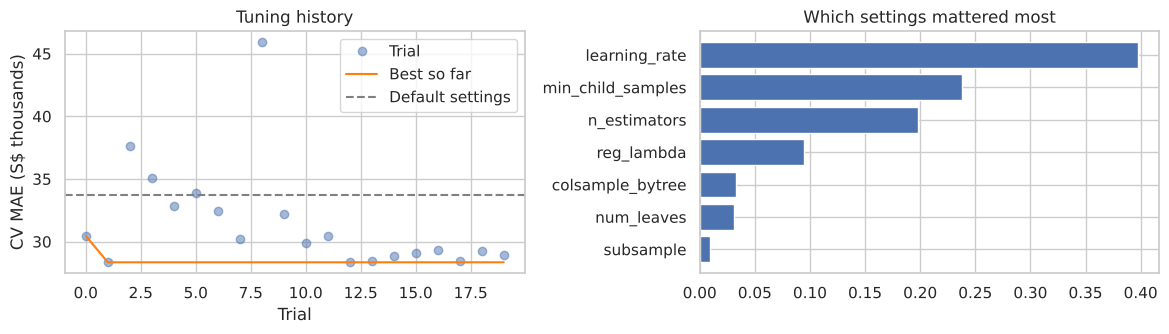

In [30]:
# Tuning history and the most important settings
history = study.trials_dataframe()["value"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(history / 1000, "o", alpha=0.5, label="Trial")
axes[0].plot(history.cummin() / 1000, color="tab:orange", label="Best so far")
axes[0].axhline(results["LightGBM (default)"]["CV MAE"] / 1000, linestyle="--", color="grey", label="Default settings")
axes[0].set_xlabel("Trial"); axes[0].set_ylabel("CV MAE (S$ thousands)"); axes[0].legend()
axes[0].set_title("Tuning history")
importance = pd.Series(optuna.importance.get_param_importances(study)).sort_values()
axes[1].barh(importance.index, importance.values)
axes[1].set_title("Which settings mattered most")
plt.tight_layout(); save("12_optuna_tuning"); plt.show()

**Insight:**
- Tuning cuts the CV MAE from **S$33,684 to S$28,352**, a saving of **S$5,332 (15.8%)**, which is far bigger than the fold-to-fold noise (about S$350). It also beats Random Forest and FLAML's best model.
- The best settings are a **bigger, slower-learning model** than the default: 900 trees (default 100), learning rate 0.06 (default 0.1), 68 leaves (default 31) and small leaves (6 flats). HDB prices have a lot of detail (town × size × lease combinations), so a richer model helps.
- **Learning rate, minimum leaf size and number of trees** mattered most.
- The best trial came early (trial 2) and the next 18 trials did not beat it, so **20 trials were enough**.
- **Overfitting:** the tuned model fits its training data more closely (Train/CV ratio 0.69 vs 0.96), but its **validation error is the lowest** of all models, so the extra detail it learns is real, not noise. The test set will confirm this.

## 10. Final test on the untouched test set

Each model is re-trained on the full training set and tested **once** on the 9,262 test sales.

In [31]:
final_models = {
    "Baseline (average price)": DummyRegressor(strategy="mean"),
    "Linear regression": make_model(LinearRegression(), scale=True),
    "PCA (95%) → Linear regression": make_model(LinearRegression(), scale=True, extra_step=("pca", PCA(n_components=0.95))),
    "Random Forest": make_model(RandomForestRegressor(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=SEED)),
    "LightGBM (default)": make_model(LGBMRegressor(random_state=SEED, verbose=-1)),
    f"FLAML best ({automl.best_estimator})": flaml_model,
    "LightGBM (tuned)": make_model(LGBMRegressor(subsample_freq=1, random_state=SEED, verbose=-1, **best_params)),
}

rows, predictions = [], {}
for name, model in final_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    rows.append({"Model": name, "MAE": mean_absolute_error(y_test, pred),
                 "RMSE": mean_squared_error(y_test, pred) ** 0.5,
                 "MAPE %": mean_absolute_percentage_error(y_test, pred) * 100,
                 "R2": r2_score(y_test, pred)})

test_table = pd.DataFrame(rows).set_index("Model").sort_values("MAE")
test_table["CV MAE"] = [results.get(name, {}).get("CV MAE", np.nan) for name in test_table.index]
test_table["Test vs CV"] = test_table["MAE"] / test_table["CV MAE"] - 1          # overfitting check
test_table.to_csv("../reports/test_results.csv")
pd.DataFrame(results).T.to_csv("../reports/cv_results.csv")
test_table.round({"MAE": 0, "RMSE": 0, "MAPE %": 2, "R2": 3, "CV MAE": 0, "Test vs CV": 3})

,MAE,RMSE,MAPE %,R2,CV MAE,Test vs CV
Model,,,,,,
LightGBM (tuned),27714.0,40328.0,4.16,0.963,28352.0,-0.022
FLAML best (lgbm),29088.0,42300.0,4.37,0.959,30138.0,-0.035
Random Forest,29136.0,42495.0,4.37,0.959,29983.0,-0.028
LightGBM (default),32772.0,46976.0,4.87,0.950,33684.0,-0.027
Linear regression,47236.0,65840.0,7.08,0.901,48207.0,-0.020
PCA (95%) → Linear regression,57508.0,82170.0,8.46,0.846,58300.0,-0.014
Baseline (average price),161745.0,209330.0,27.00,-0.000,162853.0,-0.007


**Results on the test set:**
- **The tuned LightGBM is the best model:** MAE **S$27,714**, MAPE **4.16%**, RMSE S$40,328 and **R² 0.963**. It explains 96% of the differences in price between flats.
- FLAML's best model (S$29,088) and Random Forest (S$29,136) come next. So **our tuned model beats the AutoML result** by about S$1,400 per flat.
- Linear regression (S$47,236, 7.1%) and PCA + linear regression (S$57,508, 8.5%) are much weaker.
- **Overfitting check:** every model's test MAE is within about 4% of its CV MAE (and slightly *better*), so the cross-validation scores were honest and nothing was overfitted to the validation folds.

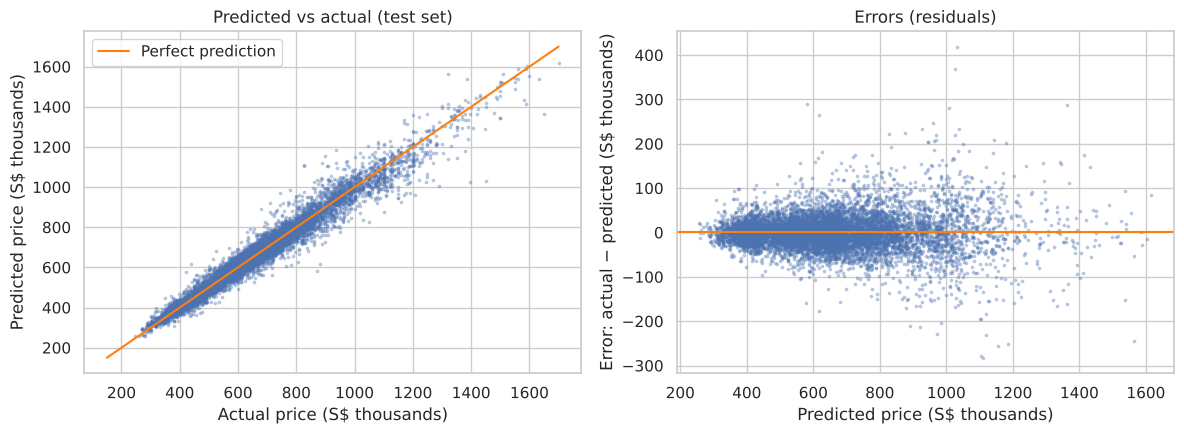

Half of the test flats are predicted within S$19,677 of the real price
90% are within S$60,289


In [32]:
# Predicted vs actual price, and errors, for the final model
final_model = final_models["LightGBM (tuned)"]
pred = predictions["LightGBM (tuned)"]
errors = y_test - pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_test / 1000, pred / 1000, s=3, alpha=0.3)
axes[0].plot([150, 1700], [150, 1700], color="tab:orange", label="Perfect prediction")
axes[0].set_xlabel("Actual price (S$ thousands)"); axes[0].set_ylabel("Predicted price (S$ thousands)")
axes[0].set_title("Predicted vs actual (test set)"); axes[0].legend()
axes[1].scatter(pred / 1000, errors / 1000, s=3, alpha=0.3)
axes[1].axhline(0, color="tab:orange")
axes[1].set_xlabel("Predicted price (S$ thousands)"); axes[1].set_ylabel("Error: actual − predicted (S$ thousands)")
axes[1].set_title("Errors (residuals)")
plt.tight_layout(); save("13_predicted_vs_actual"); plt.show()

print(f"Half of the test flats are predicted within S${errors.abs().median():,.0f} of the real price")
print(f"90% are within S${errors.abs().quantile(0.9):,.0f}")

**Insight:**
- The points sit close to the orange "perfect prediction" line across the whole price range.
- **Half of the test flats are predicted within S$19,677** of the real price, and 90% within S$60,289.
- The errors **spread out for more expensive flats** (right side of the residual plot). This is expected: a 5% miss is S$25k on a S$500k flat but S$50k on a S$1M flat. It is also why we report MAPE.
- The errors are centred on zero, so the model does not systematically over- or under-price.

In [33]:
# Is the model equally good for every kind of flat? (% error by flat type and by estate type)
check = X_test.assign(actual=y_test, pct_error=(errors.abs() / y_test * 100),
                      flat_type=df.loc[X_test.index, "flat_type"])
by_type = check.groupby("flat_type")["pct_error"].agg(["count", "mean"]).round(2)
by_estate = check.groupby("mature_estate")["pct_error"].agg(["count", "mean"]).round(2)
print("Average % error by flat type:\n", by_type, "\n")
print("Average % error, non-mature (0) vs mature (1) estates:\n", by_estate)

Average % error by flat type:
                   count  mean
flat_type                    
1 ROOM                5  3.06
2 ROOM              298  3.81
3 ROOM             2153  4.21
4 ROOM             4085  3.95
5 ROOM             2147  4.35
EXECUTIVE           573  4.91
MULTI-GENERATION      1  5.48 

Average % error, non-mature (0) vs mature (1) estates:
                count  mean
mature_estate             
0               5285  3.82
1               3977  4.61


**Insight (is the model equally good for everyone?):**
- The % error is similar across flat types: 3.8% (2-room) to 4.9% (Executive). Executives are slightly harder, as they are rarer and more varied.
- Flats in **mature estates** have a higher error (4.6% vs 3.8%). Mature towns mix very old flats with new, tall central blocks, so prices vary more for flats that look similar on paper.
- No group is badly served, but a buyer in a mature estate should treat the estimate as a slightly rougher guide.

## 11. Explainable AI: what drives the price?

We explain the final tuned LightGBM in three ways, then cross-check:
1. **Global (SHAP summary):** which features matter most, and in which direction.
2. **Feature effects (SHAP dependence):** how the price changes as one feature changes.
3. **Local (SHAP waterfall):** why *one* flat got *its* price.
4. **Cross-checks:** permutation importance, and the linear regression's coefficients.

**How to read SHAP here:** the model predicts **log(price)**, so a SHAP value of **+0.10 means roughly +10% on the price**, and −0.10 roughly −10%.

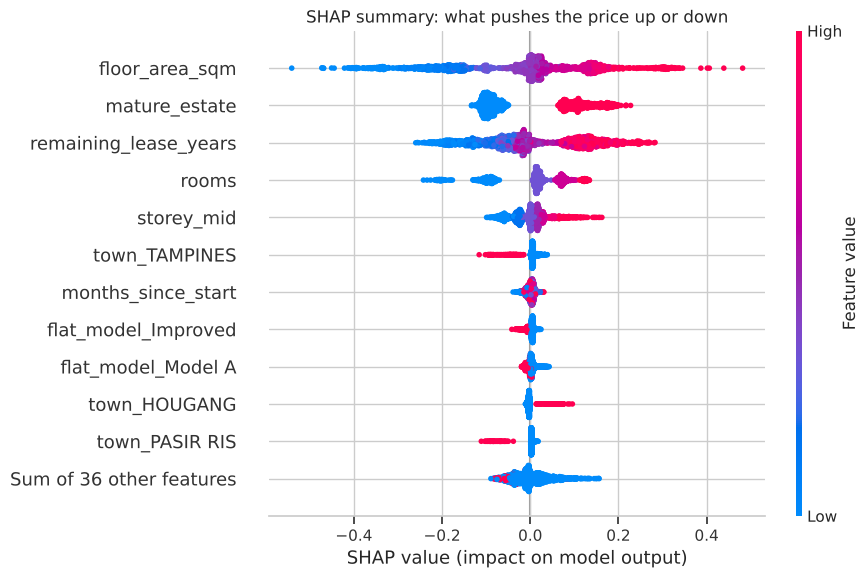

In [34]:
# SHAP values for 2,000 test flats (a sample keeps it fast)
lgbm = final_model.regressor_.named_steps["model"]
prep_fitted = final_model.regressor_.named_steps["prep"]
X_test_prep = pd.DataFrame(prep_fitted.transform(X_test), columns=prep_fitted.get_feature_names_out(), index=X_test.index)
X_shap = X_test_prep.sample(2000, random_state=SEED)

explainer = shap.TreeExplainer(lgbm)
shap_values = explainer(X_shap)

shap.plots.beeswarm(shap_values, max_display=12, show=False)
plt.title("SHAP summary: what pushes the price up or down")
save("14_shap_summary"); plt.show()

**How to read this chart:** each dot is one flat. Red = high value of the feature, blue = low. Dots to the right push the price **up**.

**Insight:**
- **Floor area:** big flats (red) push the price up by as much as +40%, small flats (blue) down by as much as −40%.
- **Mature estate:** being in a mature estate (red) adds about +10–20%; a non-mature town (blue) takes about −10% off.
- **Remaining lease:** more lease left (red) raises the price; a short lease (blue) lowers it.
- **Town columns** fine-tune the location effect. For example, Tampines (red dots on the left) is a mature estate but cheaper than most mature estates, so it pulls the price down, while Hougang pushes up for a non-mature town.

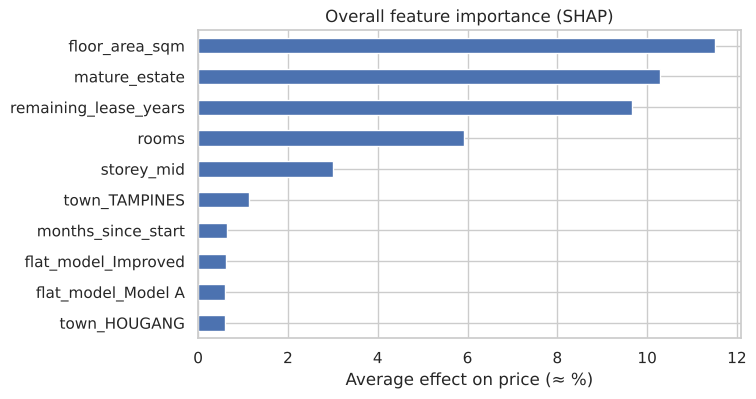

floor_area_sqm           11.5%
mature_estate            10.3%
remaining_lease_years     9.7%
rooms                     5.9%
storey_mid                3.0%
town_TAMPINES             1.1%
months_since_start        0.6%
flat_model_Improved       0.6%
dtype: str


In [35]:
# Average size of each feature's effect = overall importance
importance = pd.Series(np.abs(shap_values.values).mean(axis=0), index=X_shap.columns).sort_values(ascending=False)
(importance.head(10)[::-1] * 100).plot.barh(figsize=(7, 4))
plt.xlabel("Average effect on price (≈ %)"); plt.title("Overall feature importance (SHAP)")
save("15_shap_importance"); plt.show()
print((importance.head(8) * 100).round(1).astype(str) + "%")

**Insight:** the three biggest drivers are **floor area** (average effect about 11.5% of the price), **mature estate** (10.3%) and **remaining lease** (9.7%), then rooms (5.9%) and floor height (3.0%). The month of sale matters very little (0.6%), which matches the flat price trend in Section 3.7.

In plain words: **size, location and lease** set the price; floor height and design fine-tune it.

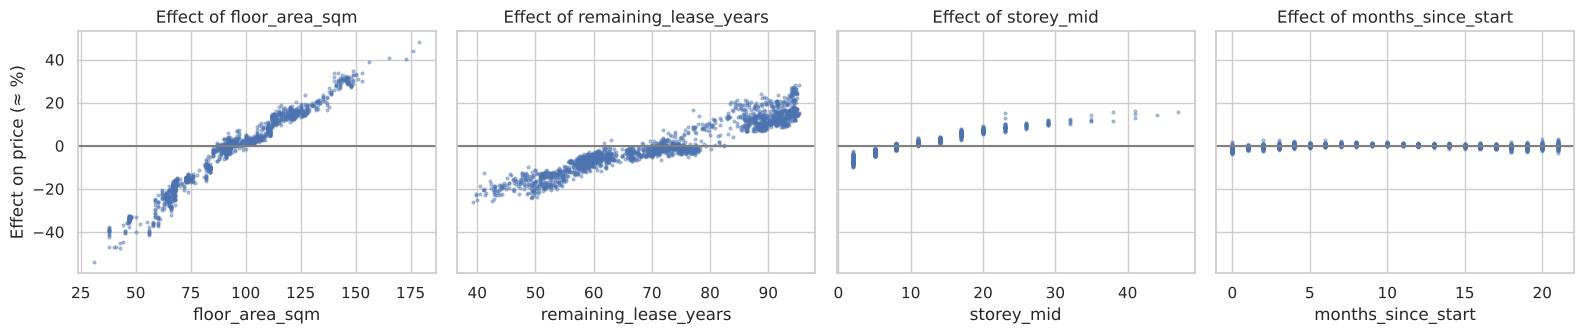

In [36]:
# How the effect on price changes as each feature changes
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, col in zip(axes, ["floor_area_sqm", "remaining_lease_years", "storey_mid", "months_since_start"]):
    ax.scatter(X_shap[col], shap_values[:, col].values * 100, s=4, alpha=0.4)
    ax.axhline(0, color="grey")
    ax.set_xlabel(col); ax.set_title(f"Effect of {col}")
axes[0].set_ylabel("Effect on price (≈ %)")
plt.tight_layout(); save("16_shap_dependence"); plt.show()

**Insight (what each feature does to the price):**
- **Floor area:** an almost straight line, from about −40% at 30 sqm to +40% at 175 sqm. Roughly **every extra 10 sqm adds about 6%**.
- **Remaining lease:** price rises slowly with lease from 40 to about 80 years, then **jumps for flats with 85+ years left** (newer flats). Buyers pay a clear premium for a young flat.
- **Floor:** low floors are about 8% below average, and the highest floors add about +15%.
- **Month of sale:** no effect, because prices were stable in 2025–2026.

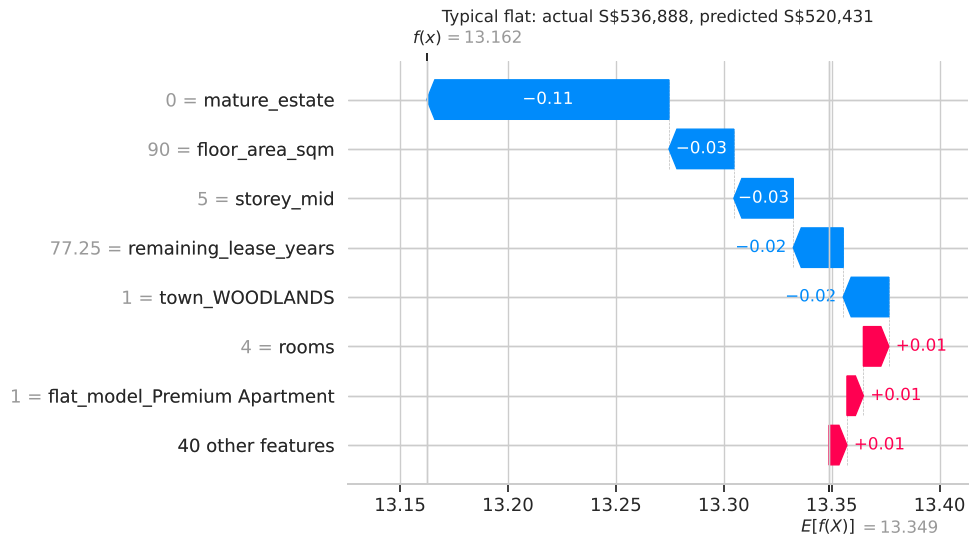

{'town': 'WOODLANDS', 'flat_type': '4 ROOM', 'flat_model': 'Premium Apartment', 'floor_area_sqm': 90.0, 'storey_range': '04 TO 06', 'remaining_lease': '77 years 03 months', 'month': '2025-12'} 



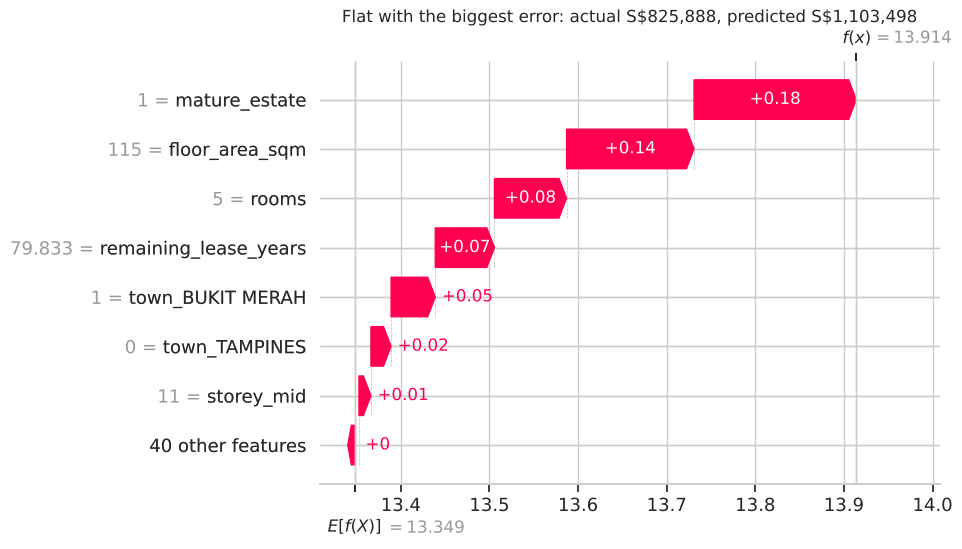

{'town': 'BUKIT MERAH', 'flat_type': '5 ROOM', 'flat_model': 'Improved', 'floor_area_sqm': 115.0, 'storey_range': '10 TO 12', 'remaining_lease': '79 years 10 months', 'month': '2025-05'} 



In [37]:
# Local explanations: one typical flat, and the flat with the biggest % error
pct_err = (errors.abs() / y_test).loc[X_shap.index]
typical = X_shap.index.get_loc(pct_err.sub(pct_err.median()).abs().idxmin())
worst = X_shap.index.get_loc(pct_err.idxmax())

for position, label, file in [(typical, "Typical flat", "17_shap_waterfall_typical"),
                              (worst, "Flat with the biggest error", "18_shap_waterfall_worst")]:
    row = X_shap.index[position]
    shap.plots.waterfall(shap_values[position], max_display=8, show=False)
    plt.title(f"{label}: actual S\\${y_test[row]:,.0f}, predicted S\\${pred[X_test.index.get_loc(row)]:,.0f}")   # \\$ = plain dollar sign in chart titles
    save(file); plt.show()
    print(df.loc[row, ["town", "flat_type", "flat_model", "floor_area_sqm", "storey_range", "remaining_lease", "month"]].to_dict(), "\n")

**Insight (two individual flats):**
- **Typical flat:** a 4-room Premium Apartment in Woodlands (90 sqm, 4th–6th floor, 77 years left, sold Dec 2025). It sold for **S$536,888**; the model predicted **S$520,431** (3% off). The main reason it is below the average flat is that Woodlands is **not a mature estate** (−0.11, about −10%); its slightly small size, low floor and the town itself take off a little more.
- **Biggest error:** a 5-room Improved flat in Bukit Merah (115 sqm, 10th–12th floor, 80 years left, sold May 2025). It sold for **S$825,888**, but the model predicted **S$1,103,498** (34% too high). Every feature points to an expensive flat: mature estate (+0.18), large (+0.14), 5 rooms and a long lease. The gap is probably due to things **the data does not include**: the exact block location, its condition, the view or a quick or family sale. A real valuation would check these.

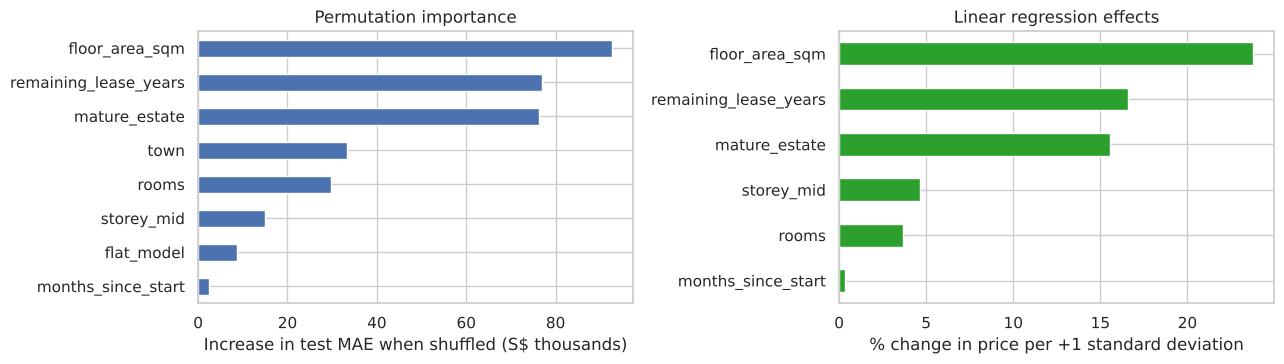

Permutation importance (S$):
 floor_area_sqm           92684.0
remaining_lease_years    76949.0
mature_estate            76383.0
town                     33335.0
rooms                    29831.0
storey_mid               14856.0
flat_model                8643.0
months_since_start        2390.0
dtype: float64

Linear effects (% per +1 SD):
 months_since_start        0.3
rooms                     3.7
storey_mid                4.7
mature_estate            15.6
remaining_lease_years    16.6
floor_area_sqm           23.8
dtype: float64


In [38]:
# Cross-check 1: permutation importance (shuffle one input column, see how much the test MAE gets worse)
perm = permutation_importance(final_model, X_test, y_test, scoring="neg_mean_absolute_error",
                              n_repeats=5, random_state=SEED)
perm_importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

# Cross-check 2: linear regression coefficients (log model, so exp(coef) - 1 = % change per 1 standard deviation)
linear = final_models["Linear regression"]
coefs = pd.Series(linear.regressor_.named_steps["model"].coef_,
                  index=linear.regressor_.named_steps["prep"].get_feature_names_out())
pct_effect = ((np.exp(coefs[NUM]) - 1) * 100).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
(perm_importance / 1000).plot.barh(ax=axes[0])
axes[0].set_xlabel("Increase in test MAE when shuffled (S$ thousands)"); axes[0].set_title("Permutation importance")
pct_effect.plot.barh(ax=axes[1], color=["tab:red" if v < 0 else "tab:green" for v in pct_effect])
axes[1].set_xlabel("% change in price per +1 standard deviation"); axes[1].set_title("Linear regression effects")
plt.tight_layout(); save("19_xai_crosscheck"); plt.show()
print("Permutation importance (S$):\n", perm_importance.sort_values(ascending=False).round(0))
print("\nLinear effects (% per +1 SD):\n", pct_effect.round(1))

**Insight (do the methods agree?):**
- **Permutation importance** (shuffling a column and measuring how much worse the test MAE gets) ranks **floor area** first (+S$92,684), then **remaining lease** (+S$76,949) and **mature estate** (+S$76,383), then town and rooms. Month of sale matters least (+S$2,390).
- **Linear regression** tells the same story: +1 standard deviation of floor area (about 24 sqm) adds **24%** to the price, +1 SD of remaining lease (about 15 years) adds **17%**, and being in a mature estate adds about **16%** per SD.
- **All three methods agree** on the top three drivers, so we can trust the explanation.
- One difference: rooms looks less important in permutation importance and linear regression than in SHAP. This is because rooms and floor area overlap (correlation 0.94), and each method splits that shared "size" effect differently.

### 11.1 Limitations of these explanations
- **Not causal.** SHAP explains what the *model* does, not what *causes* prices. For example, "mature estate adds value" may really be about distance to the city centre, which is linked to being a mature estate.
- **Linked features share credit.** Floor area and number of rooms overlap strongly, so SHAP splits the "size" effect between them, and each may look less important than size really is.
- **Sample.** SHAP used 2,000 test flats to save time; exact values would differ slightly on another sample.
- **Only what the model sees.** Distance to MRT stations, schools and renovation condition are not in the data, so the model cannot use or explain them.

## 12. Save the model and price a new flat

In [39]:
joblib.dump(final_model, "../models/hdb_price_model.joblib")

# Example: a 4-room Model A flat in Tampines, 93 sqm, 10th floor, 70 years of lease left, sold in Oct 2026
new_flat = pd.DataFrame([{"town": "TAMPINES", "flat_model": "Model A", "floor_area_sqm": 93, "rooms": 4,
                          "storey_mid": 11, "remaining_lease_years": 70, "months_since_start": 21, "mature_estate": 1}])
model = joblib.load("../models/hdb_price_model.joblib")
print(f"Predicted price: S${model.predict(new_flat)[0]:,.0f}")

Predicted price: S$649,134


## 13. Conclusions and reflection

### Did we meet the success criteria (Section 0.4)?

| Criterion | Target | Result | Met? |
|---|---|---|---|
| Beat the baseline | MAE below S$161,745 | S$27,714 | ✅ |
| Beat linear regression | MAE below S$47,236 | S$27,714 | ✅ |
| Explain most of the price | Test R² ≥ 0.90 | 0.963 | ✅ |
| Small % error | Test MAPE ≤ 8% | 4.16% | ✅ |
| No overfitting | Test MAE within 10% of CV MAE | −2.2% | ✅ |

### Key findings
1. **Size, location and remaining lease set an HDB flat's price.** Each extra 10 sqm adds about 6%, a mature estate adds about 10–20%, and flats with 85+ years of lease left carry a clear premium.
2. **Floor height adds up to about 15%;** the month of sale hardly mattered because prices were stable in 2025–2026.
3. **PCA** showed that the 7 numeric columns hold only 4 ideas (age, size, time and height), which led us to drop two duplicate lease columns. PCA + linear regression was worse, so PCA was used for understanding, not as a model step.
4. **Tree models beat linear regression by far.** AutoML pointed to LightGBM, and Optuna tuning cut its error by 15.8%.
5. **Final model: tuned LightGBM.** It is on average **S$27,714 (4.2%)** off, R² 0.963, and half of all flats are priced within about S$20,000.

### Limitations
- **Missing location detail:** no distance to MRT stations, schools or the city centre, and no information on renovation, view or facing. These explain errors like the Bukit Merah flat above.
- **Random split:** a stricter test would train on earlier months and test on the latest ones.
- **Short, stable period:** 2025–2026 prices were flat, so the model has not learned how to handle a rising or falling market.
- **SHAP is not causal:** it shows what the model uses, not what causes prices.

### Challenges and lessons learned
- **Important information was hidden in text** ("07 TO 09", "61 years 04 months"). *Lesson: look at every column's format, not just at blank values.*
- **Several columns said the same thing** (lease start, flat age and remaining lease). *Lesson: check correlations and PCA before modelling, and remove copies.*
- **A rule can have side effects:** grouping rare categories at first also merged small but expensive towns like Bukit Timah, so we changed the rule to a minimum of 50 sales. *Lesson: check what each preprocessing step actually does.*
- **AutoML needs a critical eye:** FLAML ranked Random Forest last only because it gave it few trials. *Lesson: use AutoML as a guide and confirm with your own tests.*
- **Long runs are a cost:** the first AutoML and tuning settings took too long for a class demo, so we reduced the trials and saw no real loss in accuracy.

### Next steps
Add distance to the nearest MRT station and to the city centre; test on the most recent months only; add 2020–2024 data to learn price trends; offer a simple price-estimate app for buyers.